# Market Liquidity Risk: Amihud, Bid-Ask & LVaR

Value-at-Risk assumes a position can be sold at the mid price. In March 2020 that was not true for many bonds: spreads widened tenfold and dealers' balance sheets were full. A treasury liquidity portfolio exists to be sold in a crisis, so the real question is how much it costs, and how many days it takes, to raise cash from it when markets are stressed. This notebook measures exactly that.

**What it does.** It measures the market liquidity of 12 U.S.-listed ETFs that stand in for an MDB treasury portfolio (Treasuries, agencies, munis, MBS, IG and HY credit, EM debt, equities). It estimates effective bid-ask spreads from daily prices, Amihud price impact and turnover.

Liquidity is then added to VaR (L-VaR) in two ways: the cost of crossing a stressed spread, and the market impact of selling a $500mm position over several days. The notebook ends with a LightGBM forecast of next month's liquidity against an autoregressive benchmark.

**Data.** Daily OHLC and volume since 2007 (Yahoo Finance), and the VIX and ICE BofA OAS (FRED).

**Methods.** The Corwin–Schultz (2012) high-low and Abdi–Ranaldo (2017) close-high-low spread estimators, the Roll measure, Amihud (2002) illiquidity, and the Bangia et al. (1999) exogenous L-VaR.

Endogenous liquidity uses square-root market impact with an optimal liquidation horizon, and the forecast compares LightGBM with an AR(1) on log spreads, walk-forward.

**Key output.** Liquidity rankings in calm and stressed markets (March 2020), the L-VaR uplift by asset, days to liquidate and liquidation cost by position size, and how predictable liquidity is.

## 1. Why market liquidity belongs in the risk numbers

VaR assumes a position can be sold at the mid price at the end of the horizon. For a $500mm block of municipal bonds in March 2020 that was not true. Bid-ask spreads on many bond ETFs widened tenfold and dealers' balance sheets were full. Liquidity risk shows up in two places:

- **Exogenous liquidity:** the spread every seller pays, which widens in stress. It is the same for everyone.
- **Endogenous liquidity:** the price impact of *your* trade, which grows with position size relative to the market's daily volume.

For an MDB treasury, whose liquidity portfolio exists to be sold in a crisis, the relevant question is not "what is the VaR" but "how much does it cost, and how many days does it take, to raise cash from this portfolio when markets are stressed?" Spreads are not in free daily data, so they are estimated from prices with methods validated in the microstructure literature.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import yfinance as yf
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

TICKERS = [
    "SHY",
    "IEF",
    "TLT",
    "AGZ",
    "MUB",
    "MBB",
    "LQD",
    "HYG",
    "EMB",
    "SPY",
    "IWM",
    "EEM",
]
ASSET_CLASS = {
    "SHY": "Treasuries",
    "IEF": "Treasuries",
    "TLT": "Treasuries",
    "AGZ": "Agencies",
    "MUB": "Munis",
    "MBB": "MBS",
    "LQD": "IG credit",
    "HYG": "HY credit",
    "EMB": "EM sovereign",
    "SPY": "Equity",
    "IWM": "Equity",
    "EEM": "Equity",
}
START = "2008-01-01"
# $ per asset for the liquidation analysis
POSITION = 500e6
# max share of daily volume a liquidation may take
PARTICIPATION = 0.20
# square-root impact coefficient (Almgren et al., 2005 order of magnitude)
IMPACT_ETA = 0.7
CONF = 0.99
SEED = 4

print(
    f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


CLASS_COLORS = dict(zip(sorted(set(ASSET_CLASS.values())), PALETTE))

## 3. Data: daily OHLC and volume

In [3]:
def fetch_ohlcv():
    raw = yf.download(
        TICKERS,
        start=START,
        auto_adjust=False,
        progress=False,
        group_by="column",
    )
    out = []
    for fld in ["Open", "High", "Low", "Close", "Adj Close", "Volume"]:
        f = raw[fld][TICKERS].copy()
        f.columns = [f"{c}|{fld}" for c in f.columns]
        out.append(f)
    df = pd.concat(out, axis=1)
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.index.name = "date"
    return df.reset_index()


ohlcv = cached("yahoo_ohlcv", fetch_ohlcv).set_index("date").sort_index()
ohlcv = ohlcv[ohlcv.index < pd.Timestamp.today().normalize()]
fld = lambda f: ohlcv[[f"{t}|{f}" for t in TICKERS]].set_axis(TICKERS, axis=1)
O, Hh, L, C, AC, V = (
    fld(x) for x in ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
)
ret = np.log(AC).diff()
dollar_vol = C * V
macro = pd.DataFrame({
    "VIX": fred.get_series("VIXCLS", observation_start=START),
    "HY OAS": fred.get_series(
        "BAMLH0A0HYM2",
        observation_start=(
            pd.Timestamp.today() - pd.Timedelta(days=899)
        ).strftime("%Y-%m-%d"),
    ),
})
macro.index = pd.to_datetime(macro.index)
macro = macro.reindex(ret.index).ffill()
print(
    f"{len(ret):,} days {ret.index.min():%Y-%m-%d} →"
    f" {ret.index.max():%Y-%m-%d} · median daily $ volume ($mm): "
    + ", ".join(
        f"{t} {dollar_vol[t].iloc[-250:].median() / 1e6:,.0f}" for t in TICKERS
    )
)

Crumb fetch rate-limited (HTTP 429), continuing without crumb


4,728 days 2008-01-02 → 2026-10-16 · median daily $ volume ($mm): SHY 312, IEF 743, TLT 2,637, AGZ 1, MUB 400, MBB 219, LQD 3,311, HYG 3,066, EMB 678, SPY 42,479, IWM 8,042, EEM 1,616


## 4. Liquidity measures

- **Corwin–Schultz (CS):** the daily high-low range contains both volatility and the spread. Volatility scales with the square root of the window and the spread does not, so comparing one-day and two-day ranges separates them. Negative estimates are set to zero; the measure is averaged over 21 days.
- **Abdi–Ranaldo (AR):** uses the close and the high-low mid-range; more robust in low-volatility, low-price-level assets.
- **Roll:** $2\sqrt{-\mathrm{cov}(\Delta p_t, \Delta p_{t-1})}$, from the bid-ask bounce in returns (set to zero when the covariance is positive).
- **Amihud:** $|r_t|$ / dollar volume, the price move per dollar traded, in basis points per $10mm.

All spreads are in basis points of price.

In [4]:
def corwin_schultz(h, l, window=21):
    hl = np.log(h / l) ** 2
    beta = hl + hl.shift(1)
    gamma = np.log(np.maximum(h, h.shift(1)) / np.minimum(l, l.shift(1))) ** 2
    k = 3 - 2 * np.sqrt(2)
    alpha = (np.sqrt(2 * beta) - np.sqrt(beta)) / k - np.sqrt(gamma / k)
    s = 2 * (np.exp(alpha) - 1) / (1 + np.exp(alpha))
    return s.clip(lower=0).rolling(window, min_periods=10).mean() * 1e4


def abdi_ranaldo(h, l, c, window=21):
    eta = (np.log(h) + np.log(l)) / 2
    x = (np.log(c) - eta) * (np.log(c) - eta.shift(-1))
    s2 = 4 * x.rolling(window, min_periods=10).mean()
    return np.sqrt(s2.clip(lower=0)) * 1e4


def roll(c, window=63):
    dp = np.log(c).diff()
    cov = dp.rolling(window).cov(dp.shift(1))
    return 2 * np.sqrt((-cov).clip(lower=0)) * 1e4


CS = corwin_schultz(Hh, L)
ARs = abdi_ranaldo(Hh, L, C)
RO = roll(C)
# bp per $10mm
AMI = (ret.abs() / (dollar_vol / 1e7)).rolling(21, min_periods=10).mean() * 1e4
TURN = dollar_vol.rolling(21).median()

stress_win = ("2020-03-09", "2020-03-27")
calm_win = (
    ret.index[-260].strftime("%Y-%m-%d"),
    ret.index[-1].strftime("%Y-%m-%d"),
)
summary = pd.DataFrame({
    "class": pd.Series(ASSET_CLASS),
    "CS spread, last year (bp)": CS.loc[calm_win[0] :].median(),
    "AR spread, last year (bp)": ARs.loc[calm_win[0] :].median(),
    "Roll, last year (bp)": RO.loc[calm_win[0] :].median(),
    "CS spread, Mar 2020 (bp)": CS.loc[stress_win[0] : stress_win[1]].max(),
    "Amihud, last year (bp per $10mm)": AMI.loc[calm_win[0] :].median(),
    "Amihud, Mar 2020": AMI.loc[stress_win[0] : stress_win[1]].max(),
    "median daily $ volume ($mm)": (
        dollar_vol.loc[calm_win[0] :].median() / 1e6
    ),
})
summary["stress / calm spread ×"] = (
    summary["CS spread, Mar 2020 (bp)"] / summary["CS spread, last year (bp)"]
)
summary.sort_values("CS spread, last year (bp)").round(2)

,class,"CS spread, last year (bp)","AR spread, last year (bp)","Roll, last year (bp)","CS spread, Mar 2020 (bp)","Amihud, last year (bp per $10mm)","Amihud, Mar 2020",median daily $ volume ($mm),stress / calm spread ×
SHY,Treasuries,1.09,4.00,8.79,4.72,0.20,0.34,311.44,4.32
AGZ,Agencies,2.57,11.31,17.19,23.17,84.47,48.61,1.47,9.01
MUB,Munis,4.15,0.00,3.39,30.04,0.33,3.67,397.26,7.25
MBB,MBS,4.49,7.73,18.99,29.38,1.01,1.49,220.51,6.54
IEF,Treasuries,4.49,9.54,19.16,21.56,0.29,0.99,743.07,4.80
HYG,HY credit,5.09,10.44,20.54,37.14,0.05,0.57,"3,069.79",7.29
LQD,IG credit,5.81,0.00,15.02,53.76,0.08,0.70,"3,310.59",9.25
EMB,EM sovereign,5.84,9.40,24.76,52.00,0.40,3.77,679.11,8.90
TLT,Treasuries,9.59,0.00,25.12,93.92,0.15,0.79,"2,636.81",9.79
EEM,Equity,16.34,31.90,114.99,38.07,0.65,1.26,"1,614.51",2.33


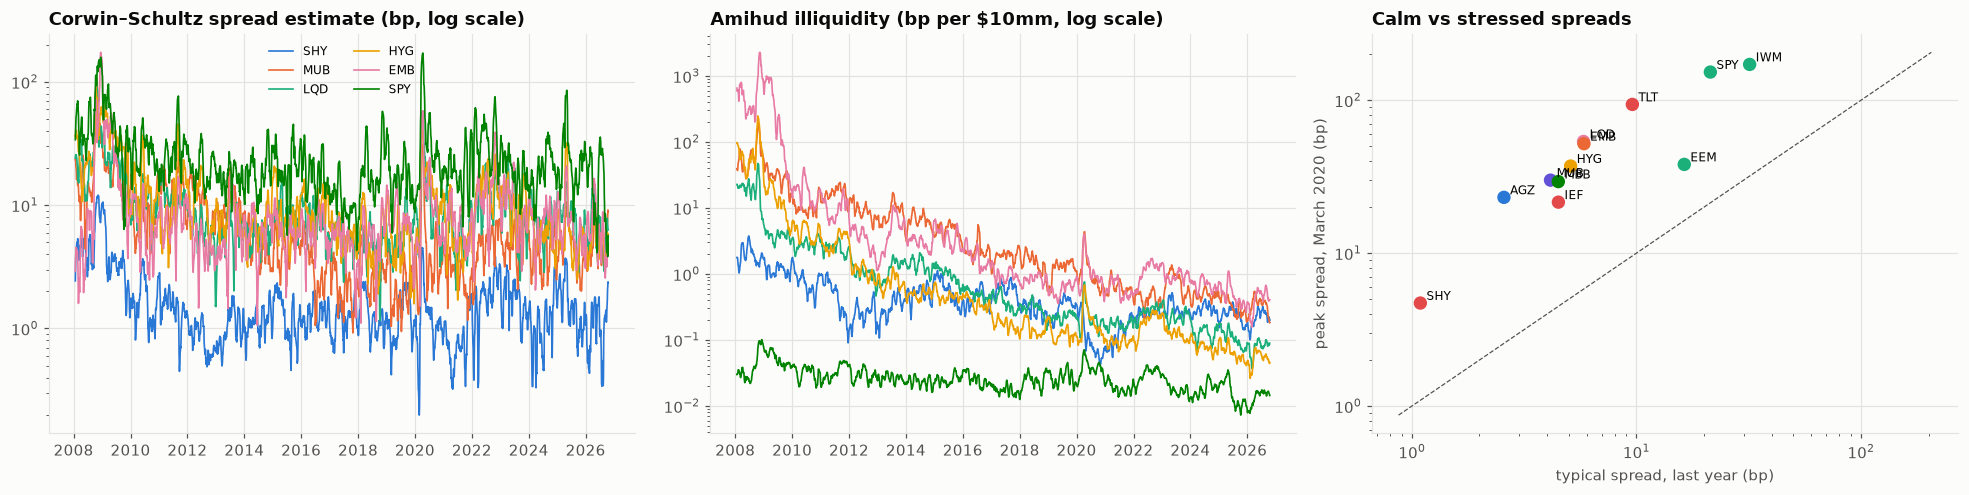

In [5]:
# --- Chart 1: liquidity through time
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
show = ["SHY", "MUB", "LQD", "HYG", "EMB", "SPY"]
for t, c in zip(show, PALETTE):
    axes[0].plot(CS.index, CS[t].rolling(5).mean(), lw=1.1, color=c, label=t)
    axes[1].plot(AMI.index, AMI[t].rolling(5).mean(), lw=1.1, color=c, label=t)
axes[0].set_yscale("log")
axes[0].set_title("Corwin–Schultz spread estimate (bp, log scale)")
axes[1].set_yscale("log")
axes[1].set_title("Amihud illiquidity (bp per $10mm, log scale)")
axes[0].legend(fontsize=8, ncol=2)
ax = axes[2]
x = summary["CS spread, last year (bp)"]
y = summary["CS spread, Mar 2020 (bp)"]
ax.scatter(x, y, s=60, c=[CLASS_COLORS[ASSET_CLASS[t]] for t in summary.index])
for t in summary.index:
    ax.annotate(
        t, (x[t], y[t]), fontsize=8, xytext=(4, 2), textcoords="offset points"
    )
lim = [min(x.min(), y.min()) * 0.8, max(x.max(), y.max()) * 1.2]
ax.plot(lim, lim, color=INK_2, ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("typical spread, last year (bp)")
ax.set_ylabel("peak spread, March 2020 (bp)")
ax.set_title("Calm vs stressed spreads")
plt.tight_layout()
save_fig(fig, "01_liquidity_measures")
plt.show()

## 5. Liquidity-adjusted VaR

**Exogenous (Bangia et al., 1999).** The 1-day 99% VaR from historical returns over the last two years, plus half the spread at a stressed level, $\tfrac12(\bar s + k\,\sigma_s)$, where $\bar s$ and $\sigma_s$ are the mean and standard deviation of the CS spread over the last two years and $k=2.33$.

**Endogenous (position size).** Selling $Q$ dollars takes $n = \lceil Q / (\pi \cdot \text{ADV}) \rceil$ days at participation $\pi = 20\%$. Each day costs half the spread plus square-root impact $\eta\,\sigma_d\sqrt{q/\text{ADV}}$, and the unsold inventory stays exposed to price risk. That risk adds $\sigma_d\sqrt{\sum_j (1-j/n)^2}$ times the position (the standard liquidation-risk term).

L-VaR is computed for the $500mm position and for stressed liquidity (ADV halved, spreads at their March 2020 peak).

In [6]:
z = stats.norm.ppf(CONF)
recent = slice(ret.index[-504], ret.index[-1])
rows = []
for t in TICKERS:
    r = ret[t].loc[recent].dropna()
    var1 = -np.quantile(r, 1 - CONF)
    s = CS[t].loc[recent].dropna() / 1e4
    exo = 0.5 * (s.mean() + z * s.std())
    sig = r.std()
    adv = dollar_vol[t].loc[recent].median()
    out = {
        "class": ASSET_CLASS[t],
        "1d VaR99 (bp)": var1 * 1e4,
        "exogenous L-VaR (bp)": (var1 + exo) * 1e4,
        "exogenous uplift %": exo / var1 * 100,
    }
    for label, adv_x, spr in [
        ("normal", adv, s.mean()),
        (
            "stressed",
            adv * 0.5,
            CS[t].loc[stress_win[0] : stress_win[1]].max() / 1e4,
        ),
    ]:
        n = int(np.ceil(POSITION / (PARTICIPATION * adv_x)))
        q = POSITION / n
        cost = 0.5 * spr + IMPACT_ETA * sig * np.sqrt(q / adv_x)
        risk = (
            z * sig * np.sqrt(sum((1 - j / n) ** 2 for j in range(n)))
            if n > 1
            else z * sig
        )
        out[f"days to sell ({label})"] = n
        out[f"liquidation cost {label} (bp)"] = cost * 1e4
        out[f"L-VaR $500mm {label} (bp)"] = (max(risk, var1) + cost) * 1e4
    rows.append(pd.Series(out, name=t))
lvar = pd.DataFrame(rows)
lvar["L-VaR $500mm stressed ($mm)"] = (
    lvar["L-VaR $500mm stressed (bp)"] / 1e4 * POSITION / 1e6
)
lvar.round(1)

,class,1d VaR99 (bp),exogenous L-VaR (bp),exogenous uplift %,days to sell (normal),liquidation cost normal (bp),L-VaR $500mm normal (bp),days to sell (stressed),liquidation cost stressed (bp),L-VaR $500mm stressed (bp),L-VaR $500mm stressed ($mm)
SHY,Treasuries,20.70,22.30,7.70,9,3.50,42.60,18,5.10,58.30,2.90
IEF,Treasuries,79.90,85.90,7.50,4,13.10,123.30,8,21.00,164.80,8.20
TLT,Treasuries,176.30,188.40,6.80,1,27.10,203.50,2,68.10,257.20,12.90
AGZ,Agencies,41.10,45.20,10.00,1484,7.60,925.20,2968,17.10,"1,314.50",65.70
MUB,Munis,69.80,74.30,6.50,6,10.40,108.00,12,23.00,153.40,7.70
MBB,MBS,79.90,87.80,9.90,11,13.80,169.20,22,24.80,237.70,11.90
LQD,IG credit,114.80,122.10,6.40,1,15.40,130.10,2,38.40,153.20,7.70
HYG,HY credit,85.90,94.90,10.50,1,12.00,97.90,2,27.50,113.40,5.70
EMB,EM sovereign,116.60,124.50,6.80,5,15.50,158.50,9,38.50,219.30,11.00
SPY,Equity,269.70,297.90,10.50,1,19.10,288.80,1,87.90,357.60,17.90


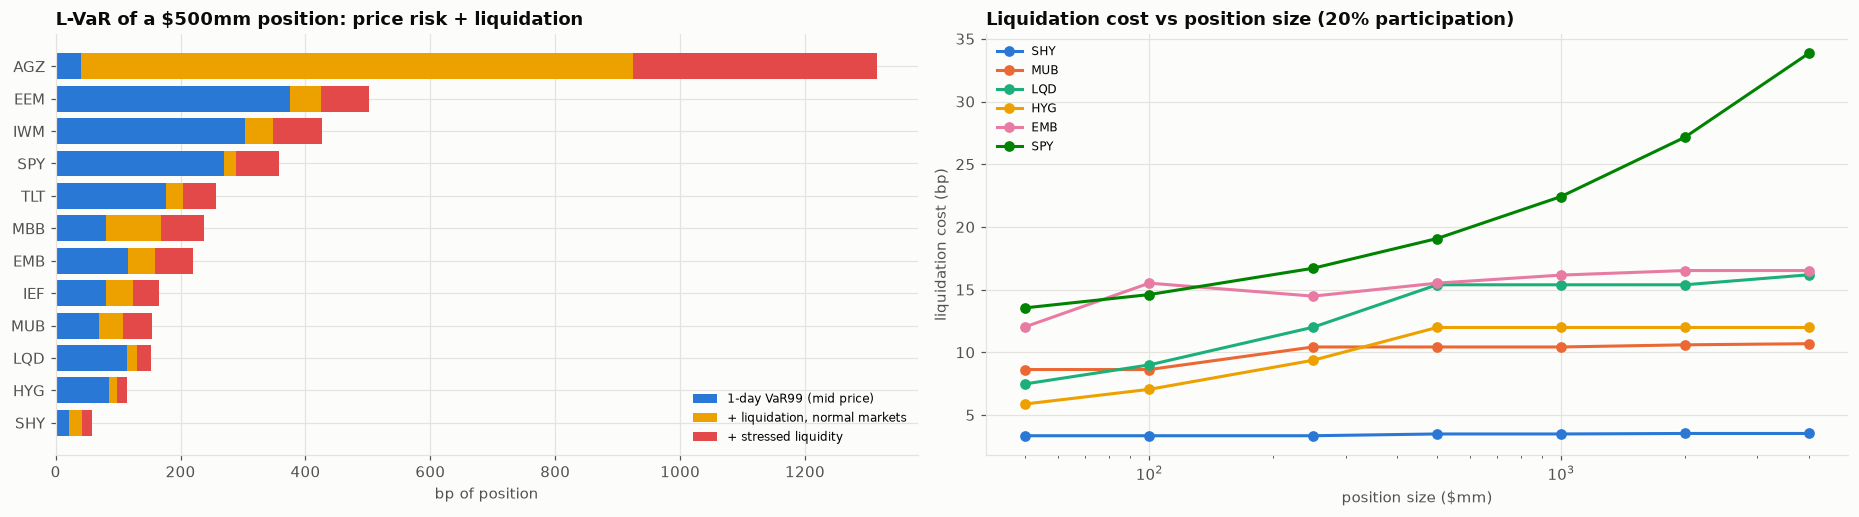

In [7]:
# --- Chart 2: L-VaR decomposition and position-size curve
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
ax = axes[0]
order = lvar.sort_values("L-VaR $500mm stressed (bp)").index
ax.barh(
    order,
    lvar.loc[order, "1d VaR99 (bp)"],
    color=PALETTE[0],
    label="1-day VaR99 (mid price)",
)
ax.barh(
    order,
    lvar.loc[order, "L-VaR $500mm normal (bp)"]
    - lvar.loc[order, "1d VaR99 (bp)"],
    left=lvar.loc[order, "1d VaR99 (bp)"],
    color=PALETTE[3],
    label="+ liquidation, normal markets",
)
ax.barh(
    order,
    lvar.loc[order, "L-VaR $500mm stressed (bp)"]
    - lvar.loc[order, "L-VaR $500mm normal (bp)"],
    left=lvar.loc[order, "L-VaR $500mm normal (bp)"],
    color=PALETTE[7],
    label="+ stressed liquidity",
)
ax.set_xlabel("bp of position")
ax.set_title("L-VaR of a $500mm position: price risk + liquidation")
ax.legend(fontsize=8)
ax = axes[1]
sizes = np.array([50, 100, 250, 500, 1000, 2000, 4000]) * 1e6
for t, c in zip(["SHY", "MUB", "LQD", "HYG", "EMB", "SPY"], PALETTE):
    r = ret[t].loc[recent].dropna()
    sig, adv = r.std(), dollar_vol[t].loc[recent].median()
    spr = CS[t].loc[recent].mean() / 1e4
    costs = []
    for Q in sizes:
        n = int(np.ceil(Q / (PARTICIPATION * adv)))
        costs.append(
            (0.5 * spr + IMPACT_ETA * sig * np.sqrt(Q / n / adv)) * 1e4
        )
    ax.plot(sizes / 1e6, costs, "o-", color=c, label=t)
ax.set_xscale("log")
ax.set_xlabel("position size ($mm)")
ax.set_ylabel("liquidation cost (bp)")
ax.set_title("Liquidation cost vs position size (20% participation)")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "02_lvar_and_position_size")
plt.show()

## 6. Is liquidity predictable? LightGBM vs AR(1)

Target: the log of next month's average CS spread for each ETF (21 trading days ahead, non-overlapping monthly samples). Features known today: the current log spread and its 3- and 12-month averages, Amihud, realised volatility, the VIX, the HY OAS change, the asset class, and the month. The benchmark is a per-asset AR(1) in log spreads. Walk-forward: refit each January from 2014 on all earlier months.

In [8]:
me = CS.resample("ME").mean()
panel = []
for t in TICKERS:
    s = np.log(me[t].clip(lower=0.1))
    df = pd.DataFrame({
        "y": s.shift(-1),
        "s0": s,
        "s3": s.rolling(3).mean(),
        "s12": s.rolling(12).mean(),
        "amihud": np.log(AMI[t].resample("ME").mean().clip(lower=1e-6)),
        "vol": ret[t].resample("ME").std() * np.sqrt(252),
        "vix": macro["VIX"].resample("ME").last(),
        "dvix": macro["VIX"].resample("ME").last().diff(),
        "month": me.index.month,
    })
    df["asset"] = t
    df["class"] = ASSET_CLASS[t]
    panel.append(df)
panel = pd.concat(panel).dropna(
    subset=["s0", "s3", "s12", "amihud", "vol", "vix"]
)
panel["asset"] = panel["asset"].astype("category")
panel["class"] = panel["class"].astype("category")
FEAT = [
    "s0",
    "s3",
    "s12",
    "amihud",
    "vol",
    "vix",
    "dvix",
    "month",
    "asset",
    "class",
]
pred = pd.DataFrame(index=panel.index.unique(), columns=TICKERS, dtype=float)
res_rows = []
for yr in range(2014, panel.index.year.max() + 1):
    tr = panel[(panel.index.year < yr) & panel["y"].notna()]
    te = panel[(panel.index.year == yr) & panel["y"].notna()]
    if te.empty:
        continue
    gbm = lgb.LGBMRegressor(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=SEED,
        verbose=-1,
    ).fit(tr[FEAT], tr["y"])
    te = te.assign(gbm=gbm.predict(te[FEAT]))
    for t in TICKERS:
        a = tr[tr["asset"] == t]
        b = te[te["asset"] == t]
        if len(a) < 24 or b.empty:
            continue
        coef = np.polyfit(a["s0"], a["y"], 1)
        te.loc[te["asset"] == t, "ar1"] = np.polyval(coef, b["s0"])
    te["rw"] = te["s0"]
    res_rows.append(te)
wf = pd.concat(res_rows)
score = pd.DataFrame({
    m: {
        "RMSE (log spread)": np.sqrt(((wf[m] - wf["y"]) ** 2).mean()),
        "RMSE stress months (VIX > 30)": np.sqrt(
            ((wf[m] - wf["y"])[wf["vix"] > 30] ** 2).mean()
        ),
        "hit rate of direction %": (
            np.sign(wf[m] - wf["s0"]) == np.sign(wf["y"] - wf["s0"])
        ).mean() * 100,
    }
    for m in ["rw", "ar1", "gbm"]
}).T.rename(
    index={
        "rw": "Random walk (no change)",
        "ar1": "AR(1) per asset",
        "gbm": "LightGBM (panel)",
    }
)
imp = pd.Series(
    gbm.booster_.feature_importance("gain"), index=FEAT
).sort_values(ascending=False)
display((imp / imp.sum() * 100).round(1).to_frame("gain %").T)
score.round(3)

,s0,s3,vol,s12,dvix,vix,asset,amihud,month,class
gain %,54.60,19.40,12.30,6.20,2.80,1.90,1.10,1.00,0.50,0.10


,RMSE (log spread),RMSE stress months (VIX > 30),hit rate of direction %
Random walk (no change),0.44,0.84,0.00
AR(1) per asset,0.40,0.76,61.44
LightGBM (panel),0.37,0.60,69.12


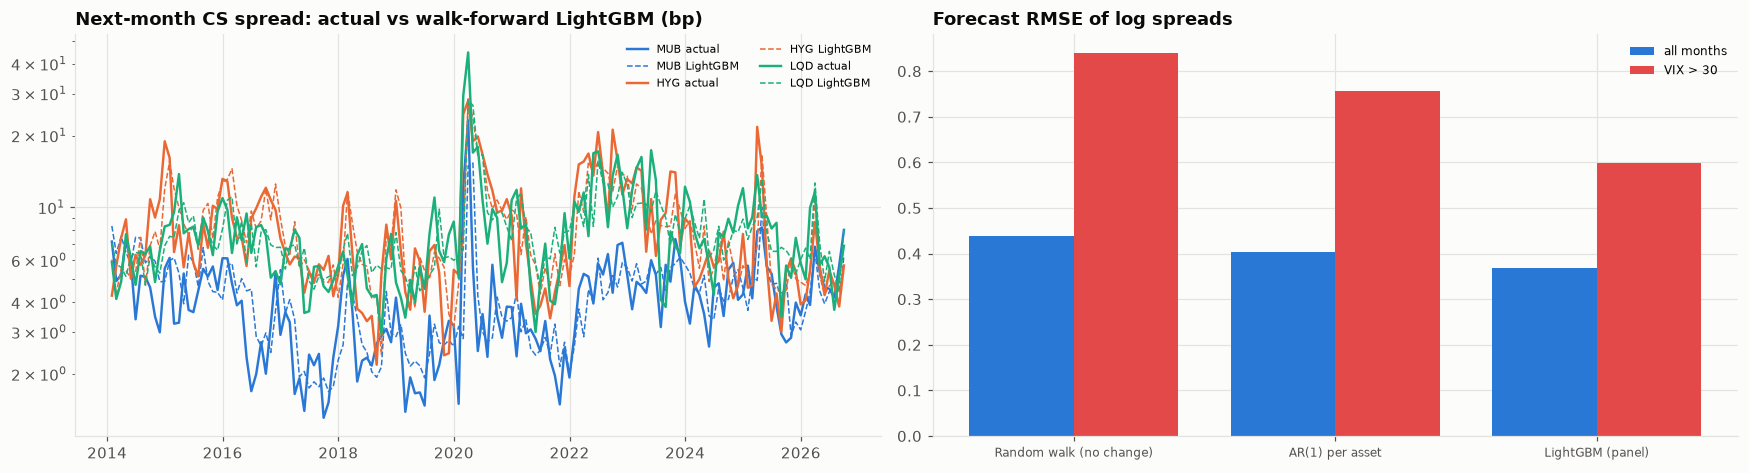

In [9]:
# --- Chart 3: forecast quality
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4))
ax = axes[0]
for t, c in zip(["MUB", "HYG", "LQD"], PALETTE):
    w = wf[wf["asset"] == t]
    ax.plot(w.index, np.exp(w["y"]), color=c, lw=1.6, label=f"{t} actual")
    ax.plot(
        w.index,
        np.exp(w["gbm"]),
        color=c,
        lw=1,
        ls="--",
        label=f"{t} LightGBM",
    )
ax.set_yscale("log")
ax.set_title("Next-month CS spread: actual vs walk-forward LightGBM (bp)")
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
xs = np.arange(len(score))
ax.bar(
    xs - 0.2,
    score["RMSE (log spread)"],
    0.4,
    color=PALETTE[0],
    label="all months",
)
ax.bar(
    xs + 0.2,
    score["RMSE stress months (VIX > 30)"],
    0.4,
    color=PALETTE[7],
    label="VIX > 30",
)
ax.set_xticks(xs, score.index, fontsize=8)
ax.set_title("Forecast RMSE of log spreads")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "03_liquidity_forecast")
plt.show()
summary.to_csv(OUT_DIR / "liquidity_summary.csv")
lvar.to_csv(OUT_DIR / "lvar_500mm.csv")
score.to_csv(OUT_DIR / "liquidity_forecast_scores.csv")

## 7. Reading the results and limitations

Twelve ETFs, January 2008 – October 2026:

**Liquidity ranking in calm markets.** Over the last year the Corwin–Schultz effective spread is about 1 bp for short Treasuries (SHY), 4–6 bp for agencies, munis, MBS and credit, and 16–32 bp for equity ETFs. The Abdi–Ranaldo estimator gives the same ordering but is noisier; it is floored at zero for TLT, MUB and LQD, where it came out negative. The Roll measure is biased upward wherever returns have positive autocorrelation, as for EEM.

**March 2020 is the test.** At the peak, spreads were **4–10 times** their recent levels: TLT 94 bp (×10), LQD 54 bp (×9), EMB 52 bp (×9), munis 30 bp (×7). Price impact rose even more for munis and EM debt (Amihud ×11 and ×9).

Short Treasuries were the only asset that stayed cheap to sell (5 bp). The high-low estimators also read some of the extreme volatility as spread, which inflates the equity numbers (SPY 153 bp), so these are upper bounds.

- **Exogenous L-VaR adds 5–13%** to a 1-day 99% VaR (Bangia et al.): the cost of crossing a stressed spread is small relative to price risk for a single day.
- **Position size changes the picture.** Selling **$500mm** at 20% of daily volume:
  - takes a day for the deep ETFs (TLT, LQD, HYG, SPY), 4–11 days for IEF, munis, EMB and MBS, and 9 days even for SHY;
  - under stressed liquidity (volume halved, March-2020 spreads), L-VaR rises to 1.1–1.6% of the position for core bonds, 2.4% for MBS and 2.2% for EM debt.
  The agency ETF (AGZ) trades only about $1.5mm a day: selling $500mm through the secondary market would take years, and its L-VaR (9–13%) is meaningless. That is the point: **ETF secondary-market volume is not the liquidity of the asset class**. A treasury holding agencies would hold the bonds, or use ETF creation and redemption, where liquidity depends on dealers, not on the exchange tape.

**Liquidity is partly predictable.** For next month's log spread, LightGBM on a panel of all ETFs beats an AR(1) per asset (RMSE 0.37 vs 0.40, against 0.44 for no change) and gets the direction right 69% of the time. Its edge is largest in stressed months (VIX above 30: 0.60 vs 0.76).

Most of its gain comes from the current spread level and its recent change, then volatility and the VIX: liquidity is persistent and worsens with volatility.

- **For an MDB liquidity buffer,** the ranking that matters is the stressed one: short Treasuries first, then intermediate Treasuries and the deep credit ETFs, with munis, MBS and EM debt as second-line sources that cost several times more to sell in a crisis. The size of each sleeve should respect days-to-liquidate limits, not just credit limits.

**Limitations**

- Spreads are estimated from daily prices, not observed quotes. TRACE or vendor bid-ask data would be the production source.
- ETF liquidity is a proxy for the underlying bonds, and in stress ETFs can trade at discounts to NAV that this analysis does not model.
- The square-root impact coefficient is a literature value, not calibrated to the bank's own trades.

## References

### Finance and regulation

- Amihud, Y. (2002). Illiquidity and stock returns: Cross-section and time-series effects. *Journal of Financial Markets, 5*(1), 31–56. https://doi.org/10.1016/S1386-4181(01)00024-6
- Corwin, S. A., & Schultz, P. (2012). A simple way to estimate bid-ask spreads from daily high and low prices. *The Journal of Finance, 67*(2), 719–760. https://doi.org/10.1111/j.1540-6261.2012.01729.x
- Abdi, F., & Ranaldo, A. (2017). A simple estimation of bid-ask spreads from daily close, high, and low prices. *The Review of Financial Studies, 30*(12), 4437–4480. https://doi.org/10.1093/rfs/hhx084
- Roll, R. (1984). A simple implicit measure of the effective bid-ask spread in an efficient market. *The Journal of Finance, 39*(4), 1127–1139. https://doi.org/10.1111/j.1540-6261.1984.tb03897.x
- Bangia, A., Diebold, F. X., Schuermann, T., & Stroughair, J. D. (2001). Modeling liquidity risk, with implications for traditional market risk measurement and management. In S. Figlewski & R. M. Levich (Eds.), *Risk management: The state of the art* (pp. 3–13). Springer. https://doi.org/10.1007/978-1-4615-0791-8_1
- Almgren, R., & Chriss, N. (2001). Optimal execution of portfolio transactions. *Journal of Risk, 3*(2), 5–40. https://doi.org/10.21314/JOR.2001.041
- Haddad, V., Moreira, A., & Muir, T. (2021). When selling becomes viral: Disruptions in debt markets in the COVID-19 crisis and the Fed's response. *The Review of Financial Studies, 34*(11), 5309–5351. https://doi.org/10.1093/rfs/hhaa145

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html